# American Sign Language (ASL) recognition with a CNN built from scratch


In [12]:
# --- Imports and global configuration -------------------------------------
import numpy as np, pandas as pd, os, glob, random, json, time
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Plot style (kept consistent across figures)
sns.set_theme(style='whitegrid', palette='muted', font_scale=0.9)
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False})
FIGURES_DIR = Path('figures'); FIGURES_DIR.mkdir(exist_ok=True)
MODELS_DIR  = Path('models');  MODELS_DIR.mkdir(exist_ok=True)

# Experiment hyper-parameters. EPOCHS is an UPPER BOUND: EarlyStopping restores the best epoch,
# so good configs converge and weak/unstable ones stop early. Raise N_PER_CLASS for more data.
IMG_SIZE     = 96     # images resized from 200x200 -> 96x96 (cost vs. signal trade-off)
BATCH        = 64
EPOCHS       = 25
N_PER_CLASS  = 3000   # full dataset: all ~3000 images per class (87k total)

## Step 0 - Kaggle authentication
The dataset lives on Kaggle, so we authenticate first. `kagglehub.login()` opens an interactive
prompt asking for your **Kaggle username** and **API key/token**. Create it at
`https://www.kaggle.com/settings` -> *Create New Token*. This works the same locally and in Colab.

In [13]:
import kagglehub
try:
    kagglehub.login()   # interactive prompt (username + API token)
except Exception as err:
    print('Interactive login not available here:', err)
    print('Alternatively place kaggle.json under ~/.kaggle/ (local) or upload it in Colab:')
    print('  from google.colab import files; files.upload()   # choose kaggle.json')

Kaggle credentials set.
Kaggle credentials successfully validated.


## Step 0b - Where to save models (persistence)
We persist each trained model together with its metrics so that **inference can load the
best-scoring model later, without retraining**. Locally this is the `./models` folder (it survives
between runs on your own machine). In Colab, set `USE_DRIVE = True` to keep the models on Google
Drive across sessions.

In [14]:
USE_DRIVE = False         # set True in Colab to persist on Google Drive across sessions
PERSIST_DIR = MODELS_DIR
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        PERSIST_DIR = Path('/content/drive/MyDrive/asl_pw1'); PERSIST_DIR.mkdir(parents=True, exist_ok=True)
    except Exception as err:
        print('Drive not available, using local folder instead:', err)
print('Persisting models to:', PERSIST_DIR.resolve())

Persisting models to: /content/models


## Step 1 - Download and dataset analysis
We download the dataset, list the classes, check the class balance and record the basic image
properties (size, colour mode, format). No data is modified here; this section is **discovery only**.

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Train dir: /kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train
Classes (29): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


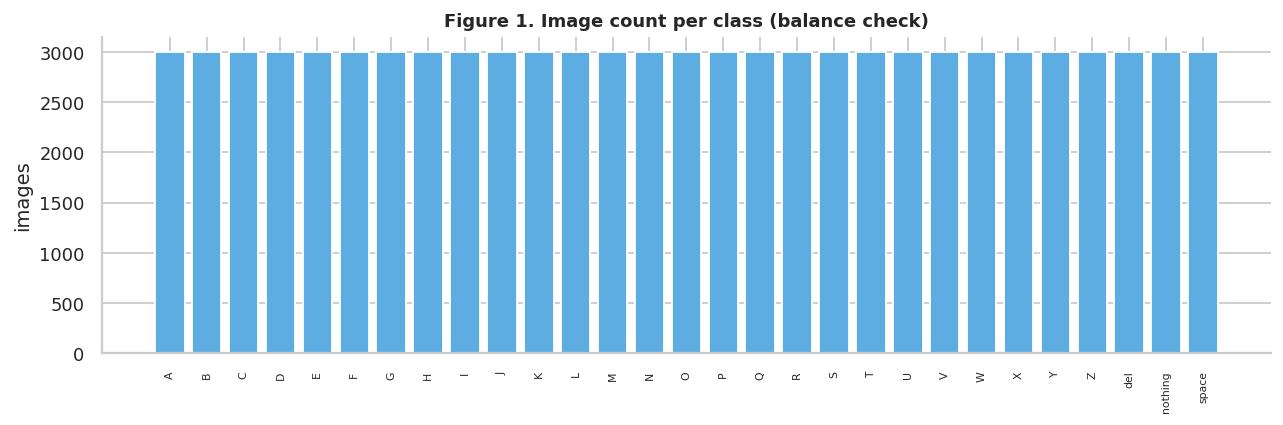

In [15]:
DATA_PATH = kagglehub.dataset_download('grassknoted/asl-alphabet')

# Locate the training directory (the folder that holds one sub-folder per class)
train_dir = None
for root, dirs, _ in os.walk(DATA_PATH):
    if sum(os.path.isdir(os.path.join(root, d)) for d in dirs) >= 29:
        train_dir = root; break
classes = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])
n_classes = len(classes)
print('Train dir:', train_dir)
print('Classes (%d):' % n_classes, classes)

# Count images per class (balance check)
counts = {c: len(glob.glob(os.path.join(train_dir, c, '*'))) for c in classes}

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(counts.keys(), counts.values(), color='#5DADE2', edgecolor='white')
ax.set_title('Figure 1. Image count per class (balance check)', fontsize=10, fontweight='bold')
ax.set_ylabel('images'); ax.tick_params(axis='x', rotation=90, labelsize=6)
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig1_classes.png', bbox_inches='tight'); plt.show()

Table 1. Dataset description
               attribute                                    value
total images (available)                                    87000
             images used                                    87000
       number of classes                                       29
     original resolution                                  200x200
             colour mode                                      RGB
             file format                                     JPEG
           class balance ~balanced (min 3000, max 3000 per class)


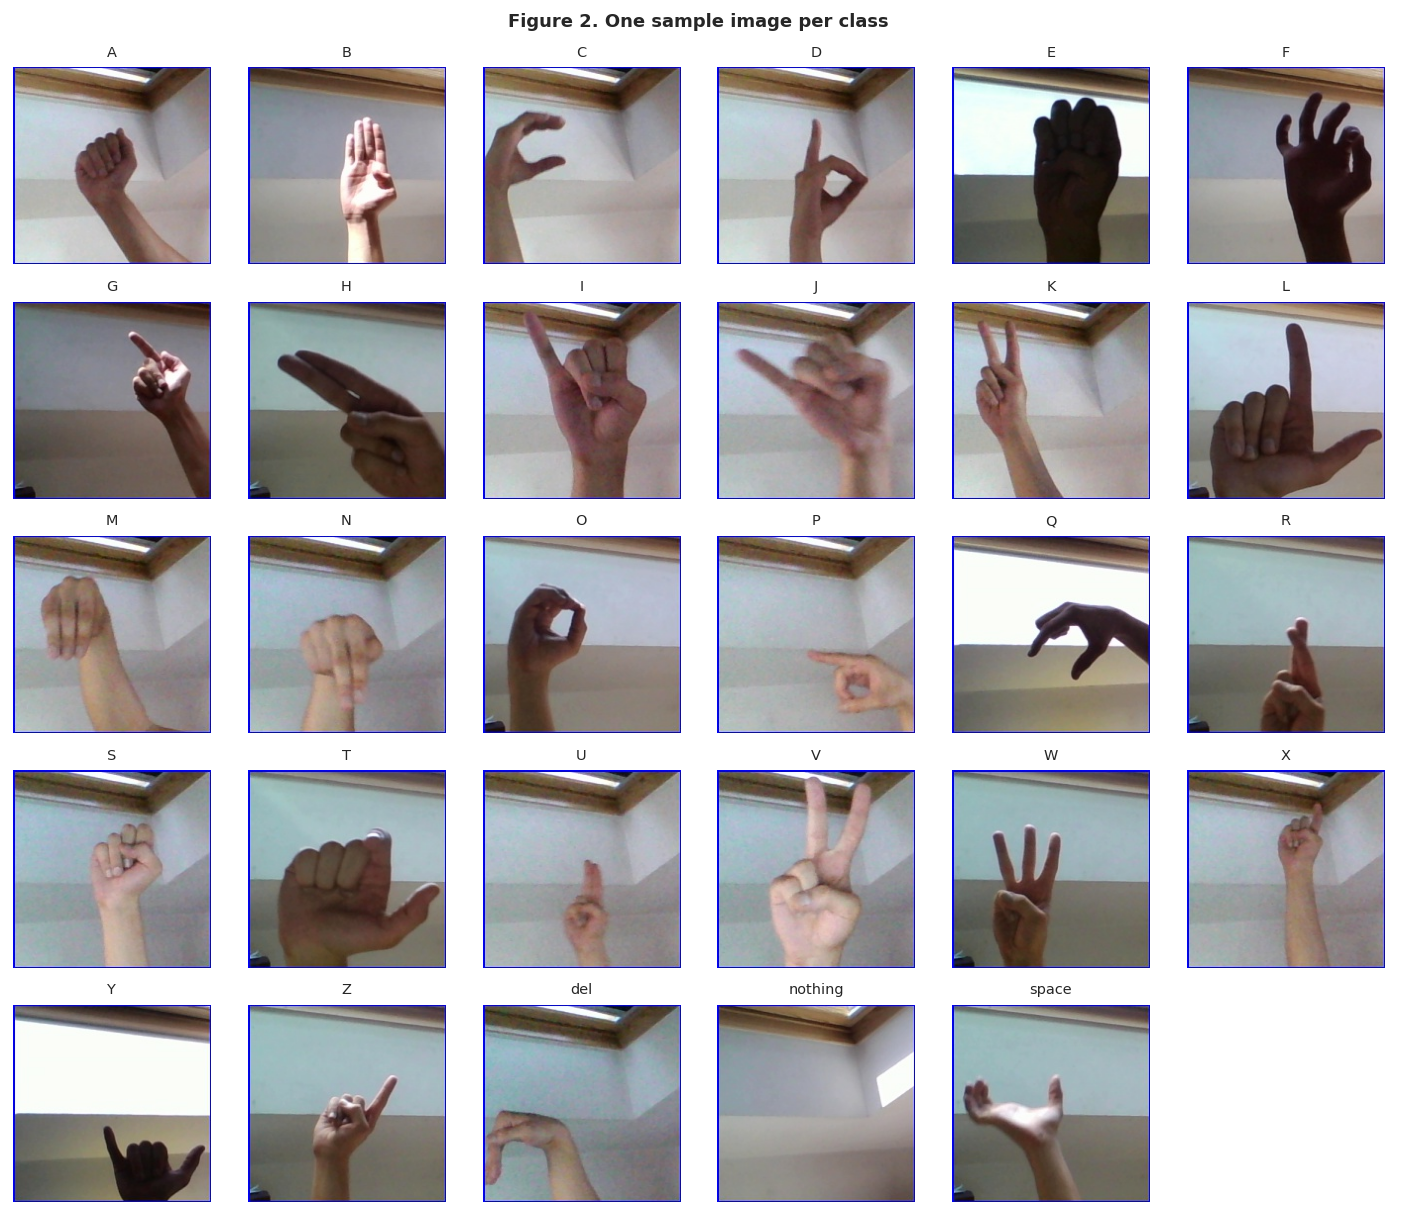

In [16]:
# Basic image properties (read one sample to report size / colour mode / format)
sample = glob.glob(os.path.join(train_dir, classes[0], '*'))[0]
im = Image.open(sample)
desc = pd.DataFrame({
    'attribute': ['total images (available)', 'images used', 'number of classes',
                  'original resolution', 'colour mode', 'file format', 'class balance'],
    'value': [sum(counts.values()), N_PER_CLASS * n_classes, n_classes,
              f'{im.size[0]}x{im.size[1]}', im.mode, im.format,
              f'~balanced (min {min(counts.values())}, max {max(counts.values())} per class)']})
print('Table 1. Dataset description')
print(desc.to_string(index=False))

# Visualise one example per class (qualitative look at every gesture)
ncol = 6; nrow = int(np.ceil(len(classes) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(11, 1.9 * nrow)); axes = axes.ravel()
for ax, c in zip(axes, classes):
    f = glob.glob(os.path.join(train_dir, c, '*'))[0]
    ax.imshow(Image.open(f)); ax.set_title(c, fontsize=8); ax.axis('off')
for k in range(len(classes), len(axes)): axes[k].axis('off')
fig.suptitle('Figure 2. One sample image per class', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig2_samples.png', bbox_inches='tight'); plt.show()

In [17]:
# Image-property audit across a sample (not just one file) -> verify acquisition consistency.
# A CNN needs uniform input, so confirm resolution and colour mode are homogeneous before resizing.
audit_paths = []
for c in classes:
    audit_paths += glob.glob(os.path.join(train_dir, c, '*'))[:12]
random.shuffle(audit_paths); audit_paths = audit_paths[:300]
props = [{'w': Image.open(p).size[0], 'h': Image.open(p).size[1], 'mode': Image.open(p).mode}
         for p in audit_paths]
pa = pd.DataFrame(props)
print('Sampled %d images across all classes:' % len(pa))
print('  unique resolutions :', pa.groupby(['w', 'h']).ngroups,
      '->', dict(list(pa.groupby(['w', 'h']).size().items())[:3]))
print('  colour modes       :', pa['mode'].value_counts().to_dict())
homogeneous = pa.groupby(['w', 'h']).ngroups == 1 and pa['mode'].nunique() == 1
print('  -> homogeneous acquisition (single resolution & colour mode)' if homogeneous
      else '  -> heterogeneous: resizing + colour-mode normalisation needed')

Sampled 300 images across all classes:
  unique resolutions : 1 -> {(200, 200): 300}
  colour modes       : {'RGB': 300}
  -> homogeneous acquisition (single resolution & colour mode)


## Step 2 - Data preparation (two datasets: DS-A and DS-B)
Preparation steps applied to every image: **resize** 200x200 -> 96x96 (lower compute cost while
keeping the hand shape readable) and **rescale** pixel values to **[0, 1]**.

To later measure the **impact of preprocessing** we build two datasets that share the **same
train/val/test split** and differ only in augmentation:

- **DS-A** - rescaled only.
- **DS-B** - rescaled + **augmentation**: brightness/contrast jitter + a small random zoom
  (implemented with `tf.image`). **No horizontal flips**, since mirroring would change the meaning
  of an ASL letter.

The split is **stratified per class** (70% train / 15% validation / 15% test). Labels are one-hot
encoded so the model can be trained with **categorical cross-entropy**.

In [23]:
# --- Stratified per-class split (70/15/15) --------------------------------
rng = np.random.default_rng(SEED)
parts = {'train': ([], []), 'val': ([], []), 'test': ([], [])}
for ci, c in enumerate(classes):
    fs = sorted(glob.glob(os.path.join(train_dir, c, '*')))[:N_PER_CLASS]
    fs = list(rng.permutation(fs))                 # shuffle within the class
    n = len(fs); a = int(0.70 * n); b = int(0.85 * n)
    for split, sl in [('train', fs[:a]), ('val', fs[a:b]), ('test', fs[b:])]:
        parts[split][0].extend(sl); parts[split][1].extend([ci] * len(sl))
splits = {k: (np.array(v[0]), np.array(v[1])) for k, v in parts.items()}
print('Split sizes:', {k: len(v[0]) for k, v in splits.items()})

# --- Input pipeline ------------------------------------------------------
def decode(path, label):
    # Read a JPEG, resize to IMG_SIZE and rescale pixels to [0,1].
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE]) / 255.0
    return img, label

def augment_img(img):
    # Light, label-preserving augmentation for DS-B (tf.image; no flips -> letter keeps meaning).
    img = tf.image.random_brightness(img, 0.12)
    img = tf.image.random_contrast(img, 0.85, 1.15)
    scale = tf.random.uniform([], 0.85, 1.0)               # random zoom-in: crop 85-100% then resize
    new = tf.cast(scale * IMG_SIZE, tf.int32)
    img = tf.image.resize(tf.image.random_crop(img, [new, new, 3]), [IMG_SIZE, IMG_SIZE])
    return tf.clip_by_value(img, 0.0, 1.0)

def make_ds(split, augment=False, shuffle=False):
    # one-hot labels enable categorical cross-entropy; val/test use shuffle=False so prediction
    # order matches splits[...] labels. We cache the decoded val/test sets in RAM (they are read
    # many times during evaluation) -> the main speed-up; train is decoded per epoch.
    f, l = splits[split]
    ds = tf.data.Dataset.from_tensor_slices((f, l))
    ds = ds.map(decode, num_parallel_calls=tf.data.AUTOTUNE)
    if split != 'train':
        ds = ds.cache()
    if shuffle:
        ds = ds.shuffle(4096, seed=SEED, reshuffle_each_iteration=True)
    if augment:
        ds = ds.map(lambda x, y: (augment_img(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x, y: (x, tf.one_hot(y, n_classes)), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_A = make_ds('train', augment=False, shuffle=True)  # DS-A: rescale only
train_B = make_ds('train', augment=True,  shuffle=True)   # DS-B: rescale + augmentation
val_ds  = make_ds('val')                                  # shared validation set (cached in RAM)
test_ds = make_ds('test')                                 # shared test set (cached in RAM)
print('DS-A = rescale only | DS-B = rescale + augmentation (brightness/contrast + zoom)')

Split sizes: {'train': 60900, 'val': 13050, 'test': 13050}
DS-A = rescale only | DS-B = rescale + augmentation (brightness/contrast + zoom)


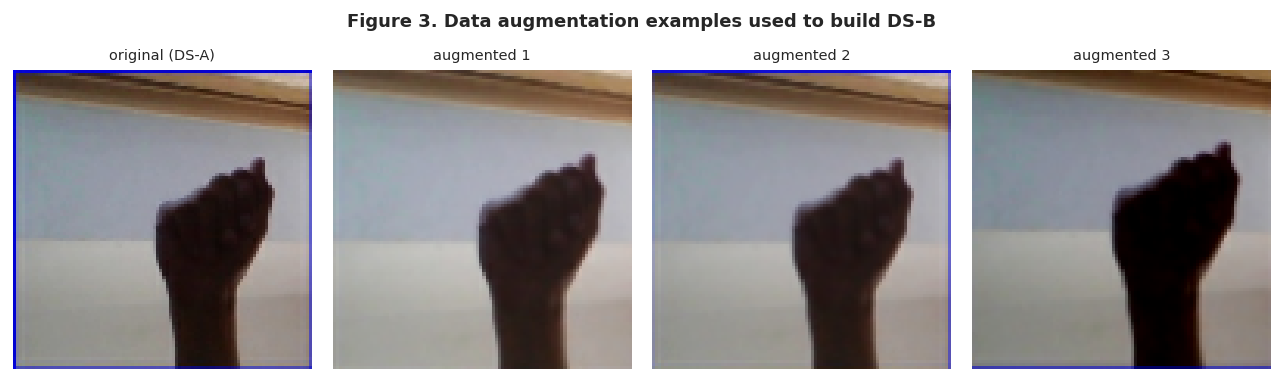

In [24]:
# Visualise the augmentation: same image, original (DS-A) vs three augmented variants (DS-B)
img0, _ = decode(splits['train'][0][0], 0)
variants = [img0] + [augment_img(img0) for _ in range(3)]
titles = ['original (DS-A)', 'augmented 1', 'augmented 2', 'augmented 3']
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, v, t in zip(axes, variants, titles):
    ax.imshow(np.clip(v.numpy(), 0, 1)); ax.set_title(t, fontsize=8); ax.axis('off')
fig.suptitle('Figure 3. Data augmentation examples used to build DS-B', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig3_augmentation.png', bbox_inches='tight'); plt.show()

## Step 3 - CNN from scratch
**Architecture:** stacked convolutional blocks with **ReLU**, batch norm and max pooling, **dropout**
before the output, a **softmax** output layer, **categorical cross-entropy** loss and the **Adam** optimizer.

The classifier head uses **GlobalAveragePooling2D** instead of Flatten: it removes the very large
dense layer (fewer parameters, less overfitting to the background) which helps generalization to
out-of-distribution images such as the bespoke own-hands set. We try several configurations varying
**kernel size**, **number of convolutional blocks**, **learning rate** and **dropout**, and train
them with **EarlyStopping** (best epoch restored).

In [25]:
def build_cnn(kernel=3, n_blocks=4, lr=1e-3, dropout=0.3):
    # CNN from scratch: n_blocks of Conv(ReLU)->BN->MaxPool, then GlobalAveragePooling + dense head.
    m = models.Sequential(name=f'cnn_k{kernel}_b{n_blocks}_d{dropout}')
    m.add(layers.Input((IMG_SIZE, IMG_SIZE, 3)))
    filt = 32
    for _ in range(n_blocks):                                # >= 4 convolutional layers
        m.add(layers.Conv2D(filt, kernel, padding='same', activation='relu'))  # ReLU hidden layer
        m.add(layers.BatchNormalization())
        m.add(layers.MaxPooling2D())
        filt = min(filt * 2, 256)
    m.add(layers.GlobalAveragePooling2D())                  # head: pool instead of Flatten
    m.add(layers.Dense(256, activation='relu'))             # ReLU hidden layer
    m.add(layers.Dropout(dropout))                           # >= 1 dropout layer
    m.add(layers.Dense(n_classes, activation='softmax'))     # softmax output
    m.compile(optimizer=optimizers.Adam(lr),                # Adam optimizer
              loss='categorical_crossentropy',               # categorical cross-entropy
              metrics=['accuracy'])
    return m

# EarlyStopping: stop when val_loss stops improving and restore the best epoch's weights.
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

# Hyper-parameter configurations (kept SEPARATE from the results table)
cnn_configs = [{'kernel': 3, 'n_blocks': 4, 'lr': 1e-3, 'dropout': 0.3},
               {'kernel': 5, 'n_blocks': 4, 'lr': 5e-4, 'dropout': 0.4},
               {'kernel': 3, 'n_blocks': 5, 'lr': 5e-4, 'dropout': 0.3}]
cfg_table = pd.DataFrame(cnn_configs)
cfg_table.index = [f'CNN_cfg{i+1}' for i in range(len(cnn_configs))]
print('Table 2. Hyper-parameter configurations')
print(cfg_table.to_string())

# Sanity-check one architecture (conv layers, dropout, softmax output)
build_cnn(**cnn_configs[0]).summary()

Table 2. Hyper-parameter configurations
          kernel  n_blocks      lr  dropout
CNN_cfg1       3         4  0.0010      0.3
CNN_cfg2       5         4  0.0005      0.4
CNN_cfg3       3         5  0.0005      0.3


Model: "cnn_k3_b4_d0.3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_20 (Conv2D)              │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 29)             │         7,453 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 463,581 (1.77 MB)

 Trainable params: 462,621 (1.76 MB)

 Non-trainable params: 960 (3.75 KB)

In [26]:
# Train every configuration on DS-A and record several validation metrics (not accuracy alone)
val_y = splits['val'][1]
cnn_results, cnn_models, cnn_hist = [], {}, {}
for i, cfg in enumerate(cnn_configs):
    name = f'CNN_cfg{i+1}'
    M = build_cnn(**cfg)
    h = M.fit(train_A, validation_data=val_ds, epochs=EPOCHS, callbacks=[EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)], verbose=0)
    yp = M.predict(val_ds, verbose=0).argmax(1)
    cnn_results.append({'model': name,
                        'epochs_run':   len(h.history['loss']),
                        'val_acc':      round((yp == val_y).mean(), 3),
                        'val_loss':     round(min(h.history['val_loss']), 3),
                        'val_f1_macro': round(f1_score(val_y, yp, average='macro'), 3)})
    cnn_models[name] = M; cnn_hist[name] = h.history
    print(name, cnn_results[-1])

res_table = pd.DataFrame(cnn_results).sort_values('val_f1_macro', ascending=False).reset_index(drop=True)
best_cnn_name = res_table.iloc[0]['model']
best_cfg = cnn_configs[int(best_cnn_name[-1]) - 1]
print('Table 3. Configuration results (sorted by macro-F1)')
print(res_table.to_string(index=False))
print('Best configuration:', best_cnn_name, best_cfg)

CNN_cfg1 {'model': 'CNN_cfg1', 'epochs_run': 19, 'val_acc': np.float64(0.967), 'val_loss': 0.11, 'val_f1_macro': 0.967}
CNN_cfg2 {'model': 'CNN_cfg2', 'epochs_run': 16, 'val_acc': np.float64(0.955), 'val_loss': 0.152, 'val_f1_macro': 0.954}
CNN_cfg3 {'model': 'CNN_cfg3', 'epochs_run': 9, 'val_acc': np.float64(0.803), 'val_loss': 0.702, 'val_f1_macro': 0.802}
Table 3. Configuration results (sorted by macro-F1)
   model  epochs_run  val_acc  val_loss  val_f1_macro
CNN_cfg1          19    0.967     0.110         0.967
CNN_cfg2          16    0.955     0.152         0.954
CNN_cfg3           9    0.803     0.702         0.802
Best configuration: CNN_cfg1 {'kernel': 3, 'n_blocks': 4, 'lr': 0.001, 'dropout': 0.3}


### 3.1 Preprocessing impact - DS-A vs DS-B
We retrain the **same best configuration** on DS-A (no augmentation) and DS-B (augmentation) and
evaluate both on the **same test set**. The augmented model (DS-B) is kept as the **final model**
and saved below.

In [27]:
test_y = splits['test'][1]
imp, imp_hist = [], {}
final_model, final_hist = None, None
for tag, ds in [('DS-A (no aug)', train_A), ('DS-B (aug)', train_B)]:
    M = build_cnn(**best_cfg)
    h = M.fit(ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)], verbose=0)
    yp = M.predict(test_ds, verbose=0).argmax(1)
    imp.append({'dataset': tag,
                'test_acc':      round((yp == test_y).mean(), 3),
                'test_f1_macro': round(f1_score(test_y, yp, average='macro'), 3)})
    imp_hist[tag] = h.history
    if tag == 'DS-B (aug)':
        final_model, final_hist = M, h.history     # final model = best config trained on DS-B
imp_table = pd.DataFrame(imp)
print('Table 4. Preprocessing impact (same best config, SAME test set)')
print(imp_table.to_string(index=False))

Table 4. Preprocessing impact (same best config, SAME test set)
      dataset  test_acc  test_f1_macro
DS-A (no aug)     0.751          0.751
   DS-B (aug)     0.943          0.941


### 3.3 Dropout ablation
We retrain the **best configuration on DS-B** twice, changing **only the dropout rate**: the chosen
value vs **no dropout (0.0)**. Comparing val/test macro-F1 measures the real effect of dropout
instead of asserting it.

In [28]:
# Best config WITH dropout (chosen value) vs WITHOUT dropout (0.0); same data + EarlyStopping.
abl = []
for d in [best_cfg['dropout'], 0.0]:
    Md = build_cnn(**{**best_cfg, 'dropout': d})
    Md.fit(train_B, validation_data=val_ds, epochs=EPOCHS,
           callbacks=[EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)], verbose=0)
    yv = Md.predict(val_ds, verbose=0).argmax(1)
    yt2 = Md.predict(test_ds, verbose=0).argmax(1)
    abl.append({'dropout': d,
                'val_f1_macro':  round(f1_score(splits['val'][1], yv, average='macro'), 3),
                'test_acc':      round((yt2 == splits['test'][1]).mean(), 3),
                'test_f1_macro': round(f1_score(splits['test'][1], yt2, average='macro'), 3)})
abl_table = pd.DataFrame(abl)
print('Table 5. Dropout ablation (best config on DS-B; only the dropout rate changes)')
print(abl_table.to_string(index=False))

Table 5. Dropout ablation (best config on DS-B; only the dropout rate changes)
 dropout  val_f1_macro  test_acc  test_f1_macro
     0.3         0.940     0.938          0.938
     0.0         0.841     0.852          0.842


### 3.2 Persist the trained model with its metrics
We save the final model **together with its metrics and training history** and append it to a
`registry.json`. This makes the evaluation below independent of the current run: the next section
loads the **best-scoring** model from disk, so the bespoke photos can be added and evaluated later
without retraining.

In [29]:
# --- Persist the best model together with its metrics, history and tables ---
def save_model_any(model, base):
    # Prefer the modern .keras format; fall back to .h5 on older TF (e.g. TF<=2.10 native Windows).
    try:
        p = str(base) + '.keras'; model.save(p); return p
    except Exception:
        p = str(base) + '.h5'; model.save(p); return p

yp = final_model.predict(test_ds, verbose=0).argmax(1); yt = splits['test'][1]
test_f1 = float(f1_score(yt, yp, average='macro')); test_acc = float((yp == yt).mean())
stamp = time.strftime('%Y%m%d_%H%M%S')
final_metrics = {'val_f1_macro': float(res_table.iloc[0]['val_f1_macro']),
                 'test_acc': test_acc, 'test_f1_macro': test_f1, 'cfg': best_cfg,
                 'img_size': IMG_SIZE, 'classes': classes, 'timestamp': stamp}
model_path = save_model_any(final_model, PERSIST_DIR / ('asl_cnn_' + stamp + ('_f1%.3f' % test_f1)))
hist_path  = str(PERSIST_DIR / ('asl_cnn_' + stamp + '_history.json'))
json.dump(final_hist, open(hist_path, 'w'))

reg_path = PERSIST_DIR / 'registry.json'
registry = json.load(open(reg_path)) if reg_path.exists() else []
registry.append({'model_path': model_path, 'hist_path': hist_path, **final_metrics})
json.dump(registry, open(reg_path, 'w'), indent=2)

# Save the report tables + the test classification report next to the model
desc.to_csv(PERSIST_DIR / 'table1_dataset.csv', index=False)
cfg_table.to_csv(PERSIST_DIR / 'table2_configs.csv')
res_table.to_csv(PERSIST_DIR / 'table3_results.csv', index=False)
imp_table.to_csv(PERSIST_DIR / 'table4_preprocessing.csv', index=False)
open(PERSIST_DIR / 'test_classification_report.txt', 'w').write(
    classification_report(yt, yp, target_names=classes, digits=3))
print('Saved model + metrics + tables to', PERSIST_DIR)
print('Registry has %d model(s); best test_f1_macro = %.3f'
      % (len(registry), max(r['test_f1_macro'] for r in registry)))

Saved model + metrics + tables to models
Registry has 1 model(s); best test_f1_macro = 0.941


## Step 4 - Evaluation of the best model
The evaluation uses the **best-scoring saved model** (loaded from disk by macro-F1), so it does not
depend on the current training run. To evaluate later **without retraining**, run Steps 0-2 (to get
`classes` and `test_ds`) plus the cells below; skip Step 3. It covers learning curves, confusion
matrices on **validation and test**, the per-class classification report, a top-3 example and the
bespoke (own-hands) test.

In [ ]:
# === Load the BEST saved model - STANDALONE ===============================
# Runs on its own: upload asl_pw1_models.zip and run this cell. No Kaggle, no training needed.
# (It also works as part of a full top-to-bottom run.)
import os, json, zipfile
import numpy as np
import tensorflow as tf, keras
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

# A model saved by a newer Keras stores 'quantization_config' in its layer configs;
# strip it so the saved model loads on any Keras 3.x version.
for _cls in (keras.layers.Dense, keras.layers.Conv2D, keras.layers.BatchNormalization):
    def _strip(orig):
        def _init(self, *a, **k):
            k.pop('quantization_config', None); return orig(self, *a, **k)
        return _init
    _cls.__init__ = _strip(_cls.__init__)

PERSIST_DIR = Path(PERSIST_DIR) if 'PERSIST_DIR' in globals() else Path('models')
PERSIST_DIR.mkdir(exist_ok=True)
FIGURES_DIR = Path(FIGURES_DIR) if 'FIGURES_DIR' in globals() else Path('figures')
FIGURES_DIR.mkdir(exist_ok=True)

# Restore the saved model from the uploaded zip if the registry is not already present.
if not (PERSIST_DIR / 'registry.json').exists():
    for _z in ['asl_pw1_models.zip', 'models.zip']:
        if os.path.exists(_z):
            zipfile.ZipFile(_z).extractall(str(PERSIST_DIR)); print('Restored saved model from', _z); break
reg_path = PERSIST_DIR / 'registry.json'
assert reg_path.exists(), 'No registry.json - upload asl_pw1_models.zip (or run training first).'

registry = json.load(open(reg_path))
best = max(registry, key=lambda r: r['test_f1_macro'])          # pick the highest test macro-F1
classes = best['classes']; n_classes = len(classes)
IMG_SIZE = int(best.get('img_size', 96))
_mp = best['model_path'] if os.path.exists(best['model_path']) else str(PERSIST_DIR / os.path.basename(best['model_path']))
eval_model = tf.keras.models.load_model(_mp, compile=False)
eval_hist = json.load(open(best['hist_path'])) if best.get('hist_path') and os.path.exists(best['hist_path']) else None

print('Registry holds %d saved model(s).' % len(registry))
print('Loaded the BEST one: %s' % os.path.basename(_mp))
print('  test macro-F1 = %.4f | test accuracy = %.4f' % (best['test_f1_macro'], best['test_acc']))
print('  config: %s' % best.get('cfg'))

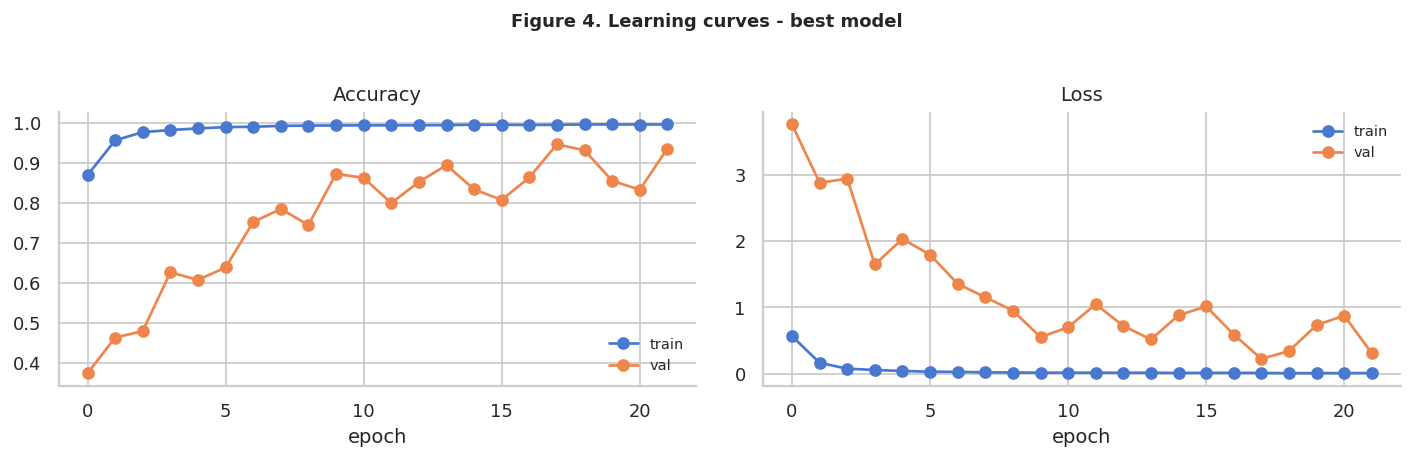

In [31]:
# Learning curves of the best model -> answers 'has the model achieved optimal training?'
if eval_hist is None:
    print('No training history stored for the loaded model; skipping the learning-curve figure.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].plot(eval_hist['accuracy'], marker='o', label='train')
    axes[0].plot(eval_hist['val_accuracy'], marker='o', label='val'); axes[0].set_title('Accuracy')
    axes[1].plot(eval_hist['loss'], marker='o', label='train')
    axes[1].plot(eval_hist['val_loss'], marker='o', label='val'); axes[1].set_title('Loss')
    for a in axes:
        a.set_xlabel('epoch'); a.legend(frameon=False, fontsize=8)
    fig.suptitle('Figure 4. Learning curves - best model', fontsize=10, fontweight='bold', y=1.03)
    plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig4_curves.png', bbox_inches='tight'); plt.show()

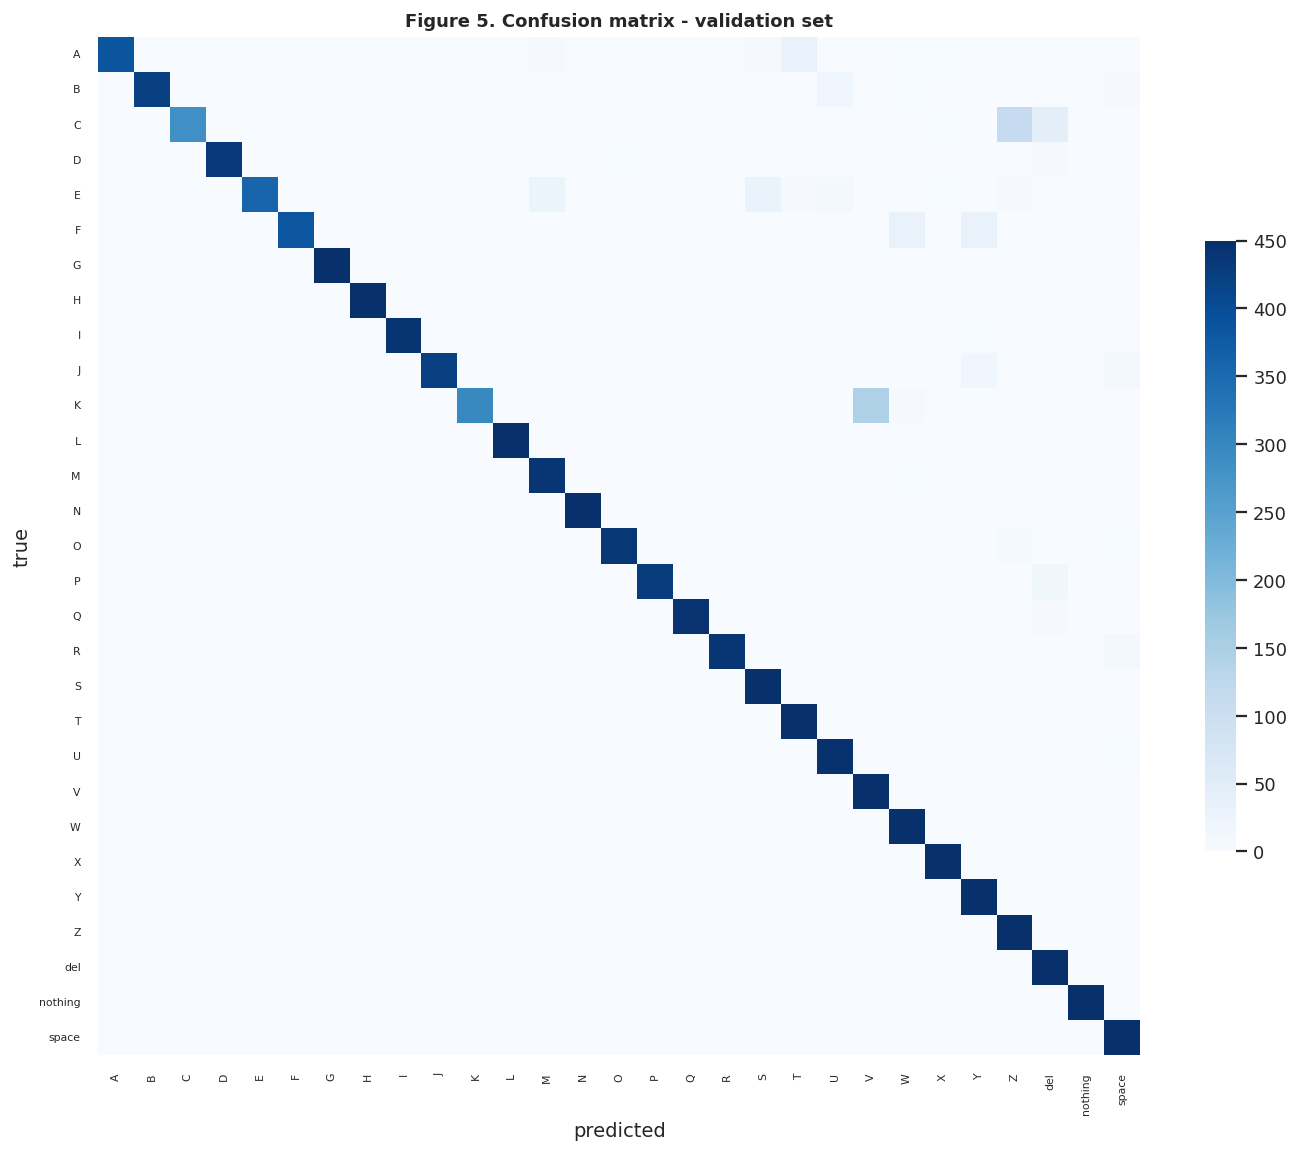

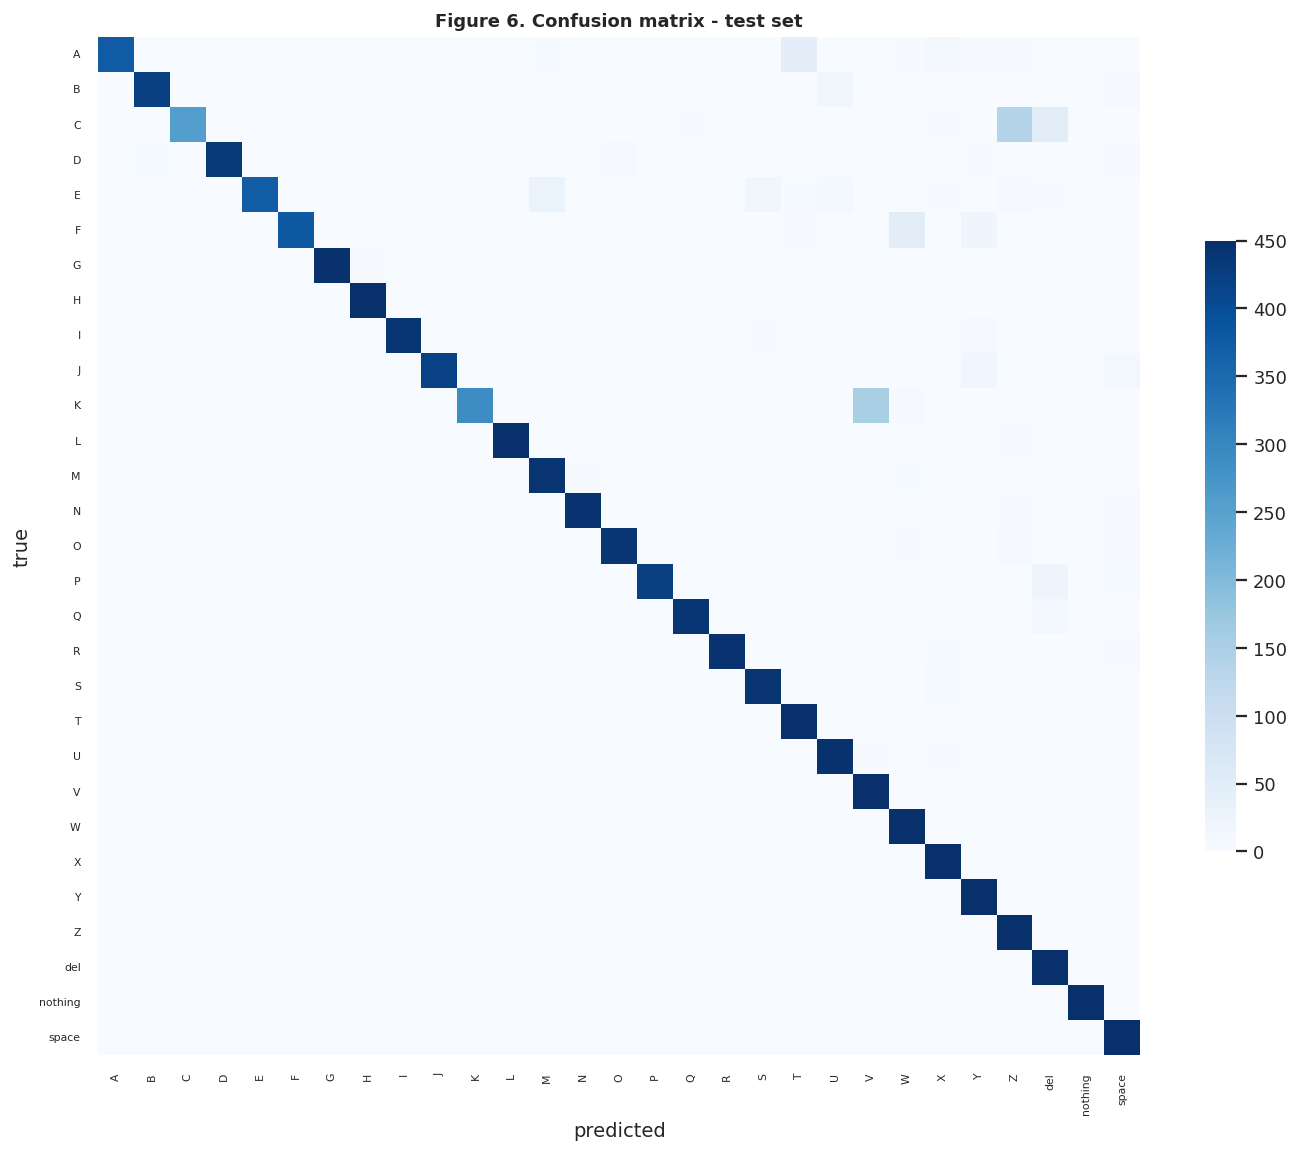

              precision    recall  f1-score   support

           A      1.000     0.836     0.910       450
           B      0.988     0.940     0.964       450
           C      1.000     0.573     0.729       450
           D      1.000     0.962     0.981       450
           E      0.997     0.827     0.904       450
           F      1.000     0.840     0.913       450
           G      1.000     0.993     0.997       450
           H      0.993     1.000     0.997       450
           I      0.998     0.978     0.988       450
           J      1.000     0.936     0.967       450
           K      1.000     0.644     0.784       450
           L      1.000     0.996     0.998       450
           M      0.927     0.982     0.954       450
           N      0.993     0.987     0.990       450
           O      0.986     0.973     0.980       450
           P      0.998     0.940     0.968       450
           Q      0.995     0.980     0.988       450
           R      1.000    

In [32]:
def plot_cm(y_true, y_pred, title, fname, cmap='Blues'):
    cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(cm, xticklabels=classes, yticklabels=classes, cmap=cmap,
                cbar_kws={'shrink': 0.6}, ax=ax)
    ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.set_title(title, fontsize=10, fontweight='bold'); ax.tick_params(labelsize=6)
    plt.tight_layout(); plt.savefig(FIGURES_DIR / fname, bbox_inches='tight'); plt.show()
    return cm

# Validation confusion matrix
yp_val = eval_model.predict(val_ds, verbose=0).argmax(1)
plot_cm(splits['val'][1], yp_val, 'Figure 5. Confusion matrix - validation set', 'fig5_cm_val.png')

# Test confusion matrix + per-class metrics (accuracy / precision / recall / F1)
yp_te = eval_model.predict(test_ds, verbose=0).argmax(1)
plot_cm(splits['test'][1], yp_te, 'Figure 6. Confusion matrix - test set', 'fig6_cm_test.png')
print(classification_report(splits['test'][1], yp_te, target_names=classes, digits=3))

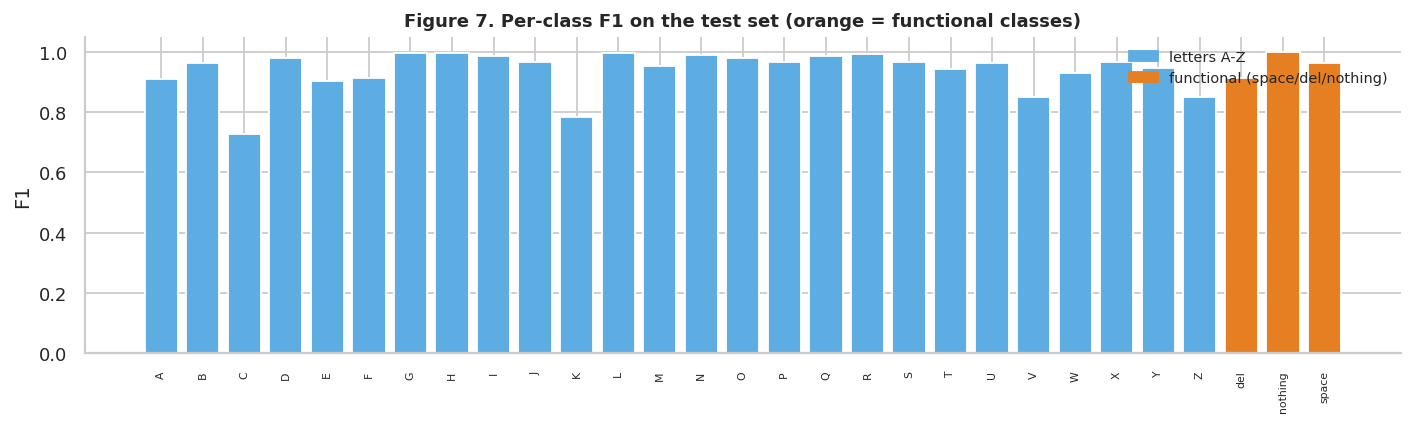

Functional-class F1: {'del': 0.914, 'nothing': 0.999, 'space': 0.964}


In [33]:
# Per-class F1 on the test set -> evidence for how the FUNCTIONAL classes (space/del/nothing)
# compare with the static letters. Uses the same test predictions (no retraining).
import matplotlib.patches as mpatches
rep = classification_report(splits['test'][1], yp_te, target_names=classes, output_dict=True, zero_division=0)
f1s = [rep[c]['f1-score'] for c in classes]
func = {'space', 'del', 'nothing'}
colors = ['#E67E22' if c in func else '#5DADE2' for c in classes]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(n_classes), f1s, color=colors, edgecolor='white')
ax.set_xticks(range(n_classes)); ax.set_xticklabels(classes, rotation=90, fontsize=6)
ax.set_ylabel('F1'); ax.set_ylim(0, 1.05)
ax.set_title('Figure 7. Per-class F1 on the test set (orange = functional classes)', fontsize=10, fontweight='bold')
ax.legend(handles=[mpatches.Patch(color='#5DADE2', label='letters A-Z'),
                   mpatches.Patch(color='#E67E22', label='functional (space/del/nothing)')],
          frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig7_perclass_f1.png', bbox_inches='tight'); plt.show()
print('Functional-class F1:', {c: round(rep[c]['f1-score'], 3) for c in classes if c in func})

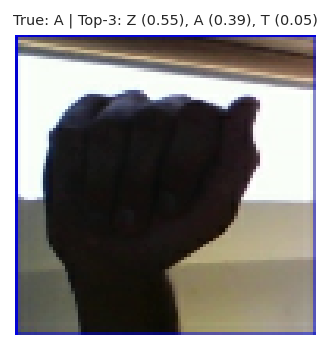

In [34]:
# Top-3 predictions for one test image (image shown next to the 3 most probable classes)
for imgs, labs in test_ds.take(1):
    x = imgs[0:1]
    true = classes[int(tf.argmax(labs[0]))]
    p = eval_model.predict(x, verbose=0)[0]
    top3 = p.argsort()[-3:][::-1]
    plt.figure(figsize=(3, 3)); plt.imshow(np.clip(imgs[0].numpy(), 0, 1)); plt.axis('off')
    plt.title('True: ' + true + ' | Top-3: ' + ', '.join(f'{classes[i]} ({p[i]:.2f})' for i in top3), fontsize=8)
    plt.savefig(FIGURES_DIR / 'fig_top3.png', bbox_inches='tight'); plt.show()
    break

### 4.1 Bespoke test set (my own hands)
Record ~12 photos (10 letters + 2 functional classes) and store them as `my_hands/<CLASS>/img.jpg`.
This cell evaluates the **best model** on them and shows the confusion matrix. The accuracy gap vs.
the official test set measures the **domain gap** (different hand, lighting and background).
Folder names are matched **case-insensitively** to the dataset classes.

In [ ]:
# === Bespoke test (your own hands) - STANDALONE ==========================
# Needs only my_hands.zip uploaded and the 'Load the BEST saved model' cell above.
# No Kaggle and no training: it reuses the loaded model as-is.
import glob
HANDS_DIR = 'my_hands'
if not os.path.isdir(HANDS_DIR) and os.path.exists('my_hands.zip'):
    zipfile.ZipFile('my_hands.zip').extractall('.'); print('Unzipped my_hands.zip')

def read_img(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return (tf.image.resize(img, [IMG_SIZE, IMG_SIZE]) / 255.0).numpy()

lut = {c.lower(): i for i, c in enumerate(classes)}
hf, hy = [], []
for p in (sorted(glob.glob(os.path.join(HANDS_DIR, '*', '*'))) if os.path.isdir(HANDS_DIR) else []):
    if p.lower().endswith(('.jpg', '.jpeg', '.png')) and os.path.basename(os.path.dirname(p)).lower() in lut:
        hf.append(p); hy.append(lut[os.path.basename(os.path.dirname(p)).lower()])

if not hf:
    print('Add your hand photos under my_hands/<CLASS>/ (or upload my_hands.zip).')
else:
    imgs = np.stack([read_img(p) for p in hf]); hy = np.array(hy)
    prob = eval_model.predict(imgs, verbose=0); hp = prob.argmax(1)
    print('Bespoke accuracy: %.3f on %d images' % ((hp == hy).mean(), len(hy)))
    present = sorted(set(hy.tolist()) | set(hp.tolist())); lab = [classes[i] for i in present]
    print(classification_report(hy, hp, labels=present, target_names=lab, zero_division=0, digits=3))

    # Figure: each own-hand photo with its 3 most probable classes.
    ncol = 4; nrow = int(np.ceil(len(hf) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.4 * nrow))
    axflat = np.ravel(axes)
    for ax in axflat:
        ax.axis('off')
    for k, ax in enumerate(axflat[:len(hf)]):
        t3 = prob[k].argsort()[-3:][::-1]
        ax.imshow(np.clip(imgs[k], 0, 1))
        ax.set_title('true: %s\n%s' % (classes[hy[k]],
                     '  '.join('%s %.2f' % (classes[i], prob[k][i]) for i in t3)),
                     fontsize=8, color=('green' if hp[k] == hy[k] else 'crimson'))
    fig.suptitle('Figure 9. Own-hand photos with the three most probable predictions',
                 fontsize=11, fontweight='bold')
    plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig9_bespoke_preds.png', bbox_inches='tight', dpi=130); plt.show()

    # Figure: bespoke confusion matrix (present classes only).
    cm = confusion_matrix(hy, hp, labels=present)
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=lab, yticklabels=lab, cmap='Greens', cbar=False, ax=ax)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.tick_params(labelsize=8)
    ax.set_title('Figure 10. Confusion matrix - bespoke (own hands) test set', fontsize=10, fontweight='bold')
    plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig10_bespoke_cm.png', bbox_inches='tight', dpi=130); plt.show()

### 4.2 Package outputs (automatic, no prompts)
Everything is already saved to disk: models/metrics/tables in `PERSIST_DIR` and figures in
`figures/`. We also zip them for convenience. **No interactive download prompt** is used: in Colab,
grab the zips from the **Files** pane (left sidebar), or set `USE_DRIVE = True` to keep them on Drive
automatically. The figures are also embedded in this notebook's outputs, so downloading the executed
`.ipynb` captures everything needed for the report.

In [36]:
import shutil
shutil.make_archive('asl_pw1_models', 'zip', str(PERSIST_DIR))   # models, metrics, tables, report
shutil.make_archive('asl_pw1_figures', 'zip', '.', 'figures')
print('Packaged asl_pw1_models.zip and asl_pw1_figures.zip in', os.getcwd())
print('Download them from the Colab Files pane, or just download this executed notebook (.ipynb).')

Packaged asl_pw1_models.zip and asl_pw1_figures.zip in /content
Download them from the Colab Files pane, or just download this executed notebook (.ipynb).
